# Student Dropout Prediction — Data Exploration

## Objective
Explore a real-world student academic success dataset
to understand its structure, features, target variable,
data quality, and suitability for machine learning.

**Dataset:** UCI ML Repository — ID 697
**Task:** Multiclass Classification

In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [37]:
# Loading the dataset
project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "data.csv"

df = pd.read_csv(data_path, sep=";")

# FIX: Strip hidden whitespace/tabs from column names and fix the 'Nacionality' typo
df.columns = df.columns.str.strip()
df.rename(columns={"Nacionality": "Nationality"}, inplace=True)

print("Dataset loaded and column names cleaned successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded and column names cleaned successfully!
Dataset shape: (4424, 37)


,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nationality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [38]:
# Checking data types, missing values, and duplicates
df.info()

print("\nData Types Summary:")
display(df.dtypes.value_counts())

print(f"\nTotal missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nationality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

int64      29
float64     7
str         1
Name: count, dtype: int64


Total missing values: 0
Duplicate rows: 0


In [39]:
# Explicitly separate integer-encoded categorical features from true numerical features
categorical_cols = [
    'Marital status', 'Application mode', 'Course', 'Daytime/evening attendance',
    'Previous qualification', 'Nationality', "Mother's qualification", 
    "Father's qualification", "Mother's occupation", "Father's occupation", 
    'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 
    'Gender', 'Scholarship holder', 'International'
]

# Note: 'Application order' (0-9) is ordinal, so we keep it with numericals for summary stats
numerical_cols = [col for col in df.columns if col not in categorical_cols and col != 'Target']

print(f"True Numerical Columns ({len(numerical_cols)}):")
for i, col in enumerate(numerical_cols, 1):
    print(f"  {i:02d}. {col}")

print(f"\nCategorical/Binary Columns ({len(categorical_cols)}):")
for i, col in enumerate(categorical_cols, 1):
    print(f"  {i:02d}. {col} ({df[col].nunique()} unique categories)")

True Numerical Columns (19):
  01. Application order
  02. Previous qualification (grade)
  03. Admission grade
  04. Age at enrollment
  05. Curricular units 1st sem (credited)
  06. Curricular units 1st sem (enrolled)
  07. Curricular units 1st sem (evaluations)
  08. Curricular units 1st sem (approved)
  09. Curricular units 1st sem (grade)
  10. Curricular units 1st sem (without evaluations)
  11. Curricular units 2nd sem (credited)
  12. Curricular units 2nd sem (enrolled)
  13. Curricular units 2nd sem (evaluations)
  14. Curricular units 2nd sem (approved)
  15. Curricular units 2nd sem (grade)
  16. Curricular units 2nd sem (without evaluations)
  17. Unemployment rate
  18. Inflation rate
  19. GDP

Categorical/Binary Columns (17):
  01. Marital status (6 unique categories)
  02. Application mode (18 unique categories)
  03. Course (17 unique categories)
  04. Daytime/evening attendance (2 unique categories)
  05. Previous qualification (17 unique categories)
  06. Nationality

In [40]:
# Descriptive statistics ONLY on true numerical features
print("Descriptive Statistics for True Numerical Features:")
display(df[numerical_cols].describe().T.round(2))

Descriptive Statistics for True Numerical Features:


,count,mean,std,min,25%,50%,75%,max
Application order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

Percentage distribution:
Target
Graduate    49.93
Dropout     32.12
Enrolled    17.95
Name: proportion, dtype: float64


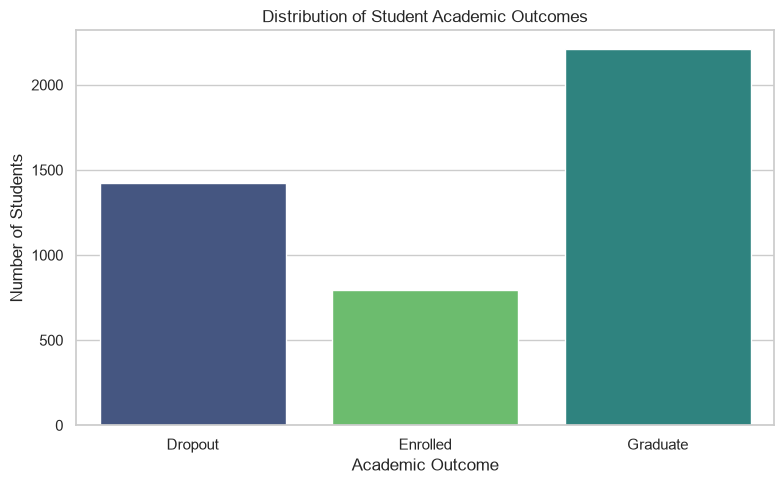

In [45]:
print(df["Target"].value_counts())

print("\nPercentage distribution:")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Target",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    palette="viridis",
    legend=False
)

plt.title("Distribution of Student Academic Outcomes")
plt.xlabel("Academic Outcome")
plt.ylabel("Number of Students")

plt.tight_layout()
plt.show()

### Observations: Target Variable Distribution (`Target`)
* **Imbalanced Multiclass Distribution:** The dataset of 4,424 students is unevenly distributed across the three academic outcomes:
  * **Graduate:** 2,209 students (**49.93%**) — *Majority Class*
  * **Dropout:** 1,421 students (**32.12%**)
  * **Enrolled:** 794 students (**17.95%**) — *Minority Class*
* **Risk of Majority Class Bias:** Because `Graduate` makes up nearly half of the dataset and `Enrolled` accounts for less than 18%, standard machine learning algorithms may become biased toward predicting `Graduate`, achieving high overall accuracy while failing to identify at-risk `Dropout` or `Enrolled` students.
* **Modeling & Evaluation Strategy:**
  * **Stratified Splitting:** We must use `stratify=y` during `train_test_split` and **Stratified K-Fold Cross-Validation** to preserve these exact class ratios in both training and testing sets.
  * **Beyond Accuracy:** Overall accuracy alone is insufficient. We will evaluate models using **Macro-Averaged F1-Score, Precision, Recall**, and **Confusion Matrices**, and explore `class_weight="balanced"` to penalize misclassifications of the minority classes.

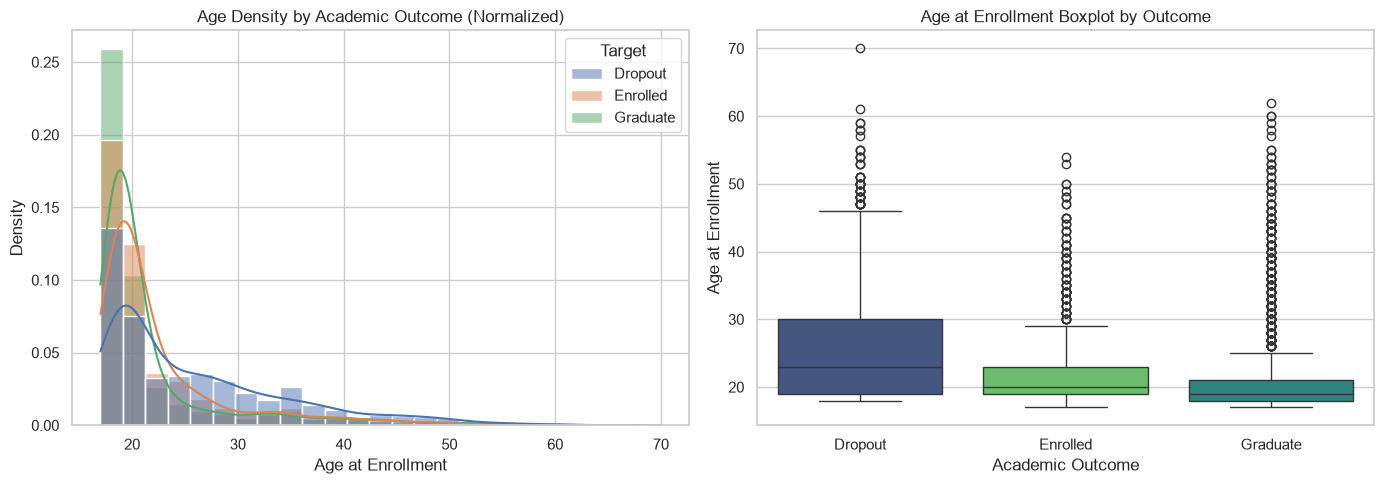

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left plot: Normalized density to account for class imbalance
sns.histplot(
    data=df,
    x="Age at enrollment",
    hue="Target",
    hue_order=["Dropout", "Enrolled", "Graduate"],
    bins=25,
    stat="density",
    common_norm=False,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Age Density by Academic Outcome (Normalized)")
axes[0].set_xlabel("Age at Enrollment")
axes[0].set_ylabel("Density")

# Right plot: Boxplot to clearly see median and quartile age differences
sns.boxplot(
    data=df,
    x="Target",
    y="Age at enrollment",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    palette="viridis",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Age at Enrollment Boxplot by Outcome")
axes[1].set_xlabel("Academic Outcome")
axes[1].set_ylabel("Age at Enrollment")

plt.tight_layout()
plt.show()

# Observation:
# Graduate students are heavily concentrated around ages 18-20 (median = 19),
# whereas Dropout students have a higher median age and a much wider interquartile range.

### Observations: Age at Enrollment vs. Academic Outcome
* **Younger Students Graduate at Higher Rates:** The `Graduate` group is heavily concentrated between **18 and 21 years old** (median age = **19**), with a very tight interquartile range.
* **Older Students Face Higher Dropout Risk:** The `Dropout` group has a noticeably higher median age (~**23 years old**) and a much wider spread (75th percentile reaches age **30**, with whiskers extending to **46**). 
* **Density Crossover (Age 23+):** In the normalized density plot on the left, the blue `Dropout` curve overtakes the green `Graduate` curve starting around **age 23**. This indicates that mature students (who often balance work, family, or financial responsibilities alongside evening classes) are significantly more likely to drop out than students entering university directly from high school.
* **Modeling Note:** `Age at enrollment` is heavily right-skewed with outliers up to age 70. Tree-based models (Random Forest, XGBoost) handle this naturally, but for linear models or neural networks, applying a log transformation or `RobustScaler` will be beneficial.

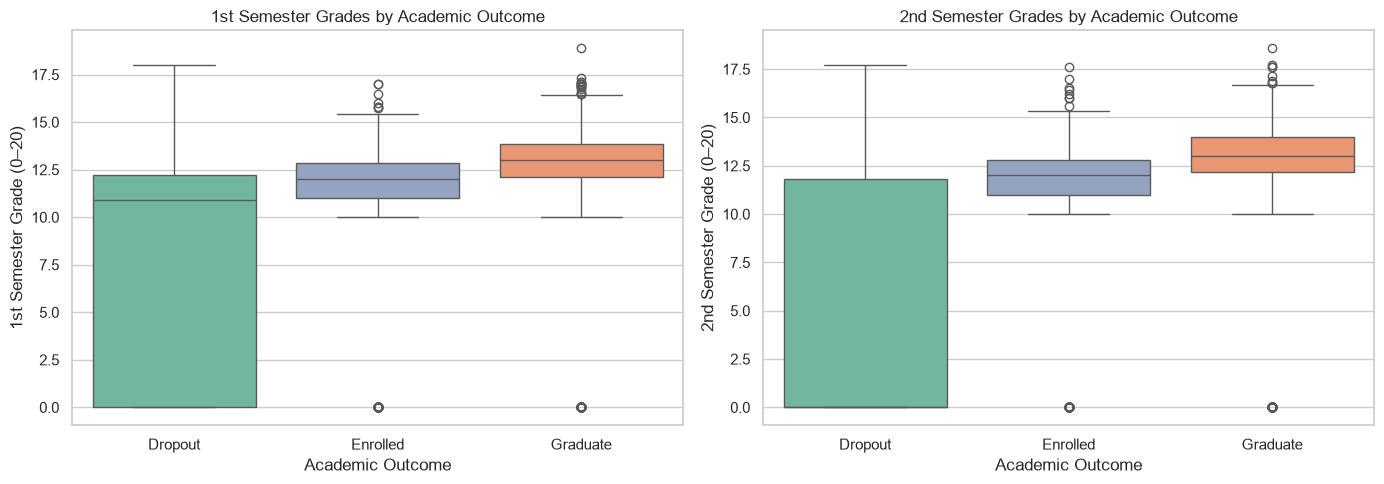

Count of students with a 0.0 Grade by Academic Outcome:


,1st Sem (Grade == 0),2nd Sem (Grade == 0)
Target,,
Dropout,570,727
Graduate,77,75
Enrolled,71,68


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1st Semester Grades
sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 1st sem (grade)",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    palette="Set2",
    legend=False,
    ax=axes[0]
)
axes[0].set_title("1st Semester Grades by Academic Outcome")
axes[0].set_xlabel("Academic Outcome")
axes[0].set_ylabel("1st Semester Grade (0–20)")

# 2nd Semester Grades
sns.boxplot(
    data=df,
    x="Target",
    y="Curricular units 2nd sem (grade)",
    order=["Dropout", "Enrolled", "Graduate"],
    hue="Target",
    palette="Set2",
    legend=False,
    ax=axes[1]
)
axes[1].set_title("2nd Semester Grades by Academic Outcome")
axes[1].set_xlabel("Academic Outcome")
axes[1].set_ylabel("2nd Semester Grade (0–20)")

plt.tight_layout()
plt.show()

# Investigate the 0.0 grade anomaly across classes
print("Count of students with a 0.0 Grade by Academic Outcome:")
zero_grades = pd.DataFrame({
    "1st Sem (Grade == 0)": df[df["Curricular units 1st sem (grade)"] == 0]["Target"].value_counts(),
    "2nd Sem (Grade == 0)": df[df["Curricular units 2nd sem (grade)"] == 0]["Target"].value_counts()
}).fillna(0).astype(int)
display(zero_grades)

### Observations: 1st & 2nd Semester Grades vs. Academic Outcome
* **Clear Separation Across Outcomes:** There is a distinct upward progression in median grades from `Dropout` $\rightarrow$ `Enrolled` (~12.0) $\rightarrow$ `Graduate` (~13.0) in both semesters.
* **The "Zero Grade" Phenomenon:** In the Portuguese higher education grading scale (0–20), passing grades range from **10 to 20** (which is why the bottom whiskers for `Enrolled` and `Graduate` stop cleanly at `10.0`, with `0.0` appearing only as rare outliers). A grade of `0.0` indicates the student **did not pass or attend any evaluations** that semester.
* **2nd Semester Collapse for Dropouts:** In the 1st semester, the `Dropout` median grade is still around **10.9**, though the 25th percentile is already `0.0`. By the **2nd semester**, the `Dropout` median collapses all the way to **`0.0`** (over half of all dropouts pass zero courses in semester 2). 
* **Modeling Note:** `Curricular units 2nd sem (grade)` and `Curricular units 2nd sem (approved)` will be among the strongest predictors of student dropout. Creating an engineered feature for **"Grade Drop"** (`2nd sem grade - 1st sem grade`) or **"Pass Rate"** (`approved / enrolled`) will likely boost model performance.

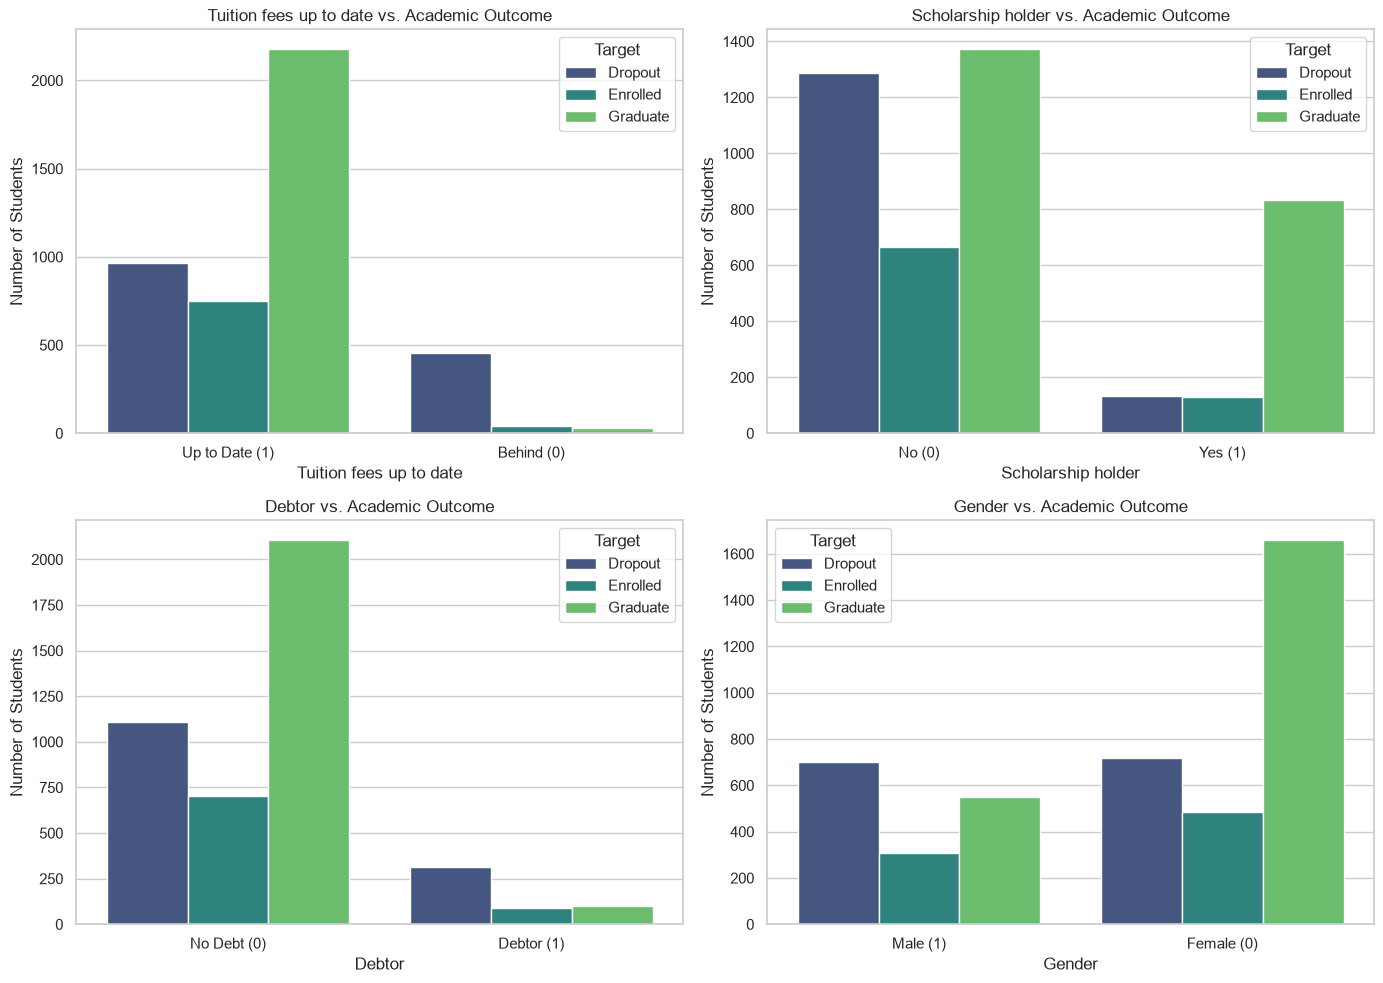

In [43]:
key_binaries = [
    ("Tuition fees up to date", {0: "Behind (0)", 1: "Up to Date (1)"}),
    ("Scholarship holder", {0: "No (0)", 1: "Yes (1)"}),
    ("Debtor", {0: "No Debt (0)", 1: "Debtor (1)"}),
    ("Gender", {0: "Female (0)", 1: "Male (1)"})
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, (col, label_map) in enumerate(key_binaries):
    temp_series = df[col].map(label_map)
    sns.countplot(
        x=temp_series,
        hue=df["Target"],
        hue_order=["Dropout", "Enrolled", "Graduate"],
        palette="viridis",
        ax=axes[i]
    )
    axes[i].set_title(f"{col} vs. Academic Outcome")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Number of Students")

plt.tight_layout()
plt.show()

### Observations: Financial & Demographic Features vs. Academic Outcome
* **Tuition Fees Up to Date (Critical Predictor):** Students who are `Behind (0)` on their tuition fees almost exclusively end up in the `Dropout` category (over **85%** dropout rate), with virtually zero graduates. Financial compliance is one of the strongest early warning signals in the dataset.
* **Scholarship Holders Graduate at High Rates:** Students with a scholarship (`Yes (1)`) have a massive graduation advantage—the `Graduate` bar towers over the `Dropout` and `Enrolled` bars. Conversely, non-scholarship holders (`No (0)`) have nearly equal numbers of dropouts and graduates.
* **Debt Status:** Similar to tuition status, students flagged as `Debtor (1)` are predominantly in the `Dropout` class, whereas non-debtors (`No Debt (0)`) are majority `Graduate`.
* **Gender Disparity:** While `Female (0)` students make up the majority of the student body and graduate at a very high rate (more than 2x as many graduates as dropouts), `Male (1)` students exhibit a much higher dropout rate—there are actually **more male dropouts than male graduates**.

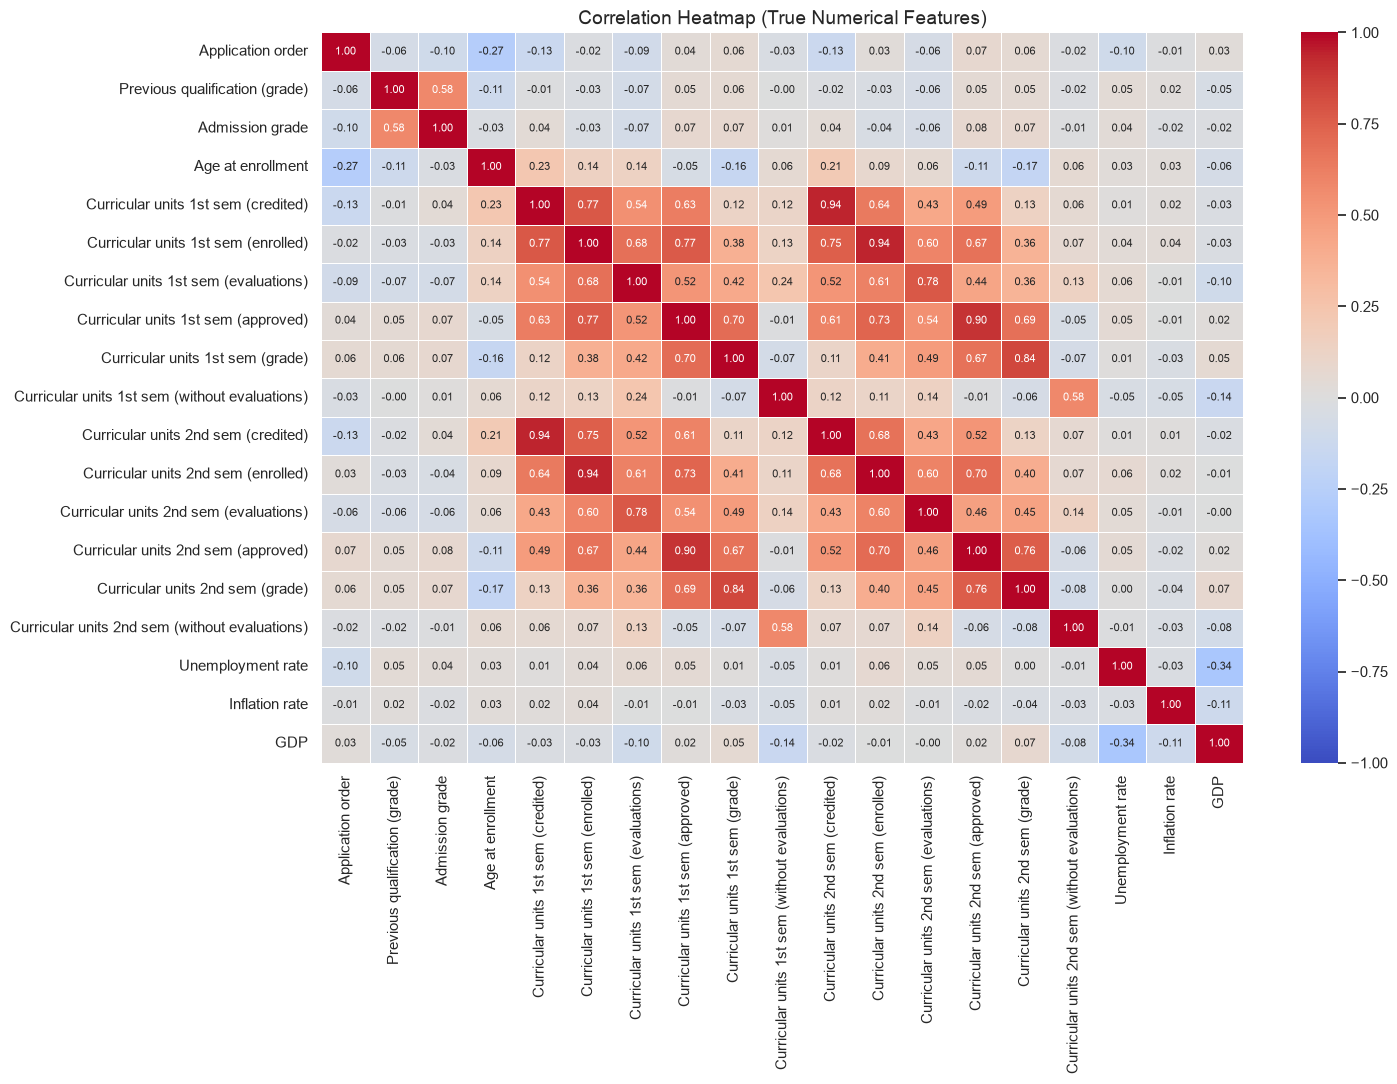

In [44]:
plt.figure(figsize=(15, 11))
corr_matrix = df[numerical_cols].corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    annot_kws={"size": 8}
)
plt.title("Correlation Heatmap (True Numerical Features)", fontsize=14)
plt.tight_layout()
plt.show()

### Observations: Correlation Heatmap (True Numerical Features)
* **Strong Multicollinearity Across Semesters (1st Sem vs. 2nd Sem):** 
  * `1st sem (credited)` and `2nd sem (credited)` have a correlation of **$r = 0.94$**.
  * `1st sem (enrolled)` and `2nd sem (enrolled)` have a correlation of **$r = 0.94$**.
  * `1st sem (approved)` and `2nd sem (approved)` have a correlation of **$r = 0.90$**.
  * `1st sem (grade)` and `2nd sem (grade)` have a correlation of **$r = 0.84$**.
  * `1st sem (evaluations)` and `2nd sem (evaluations)` have a correlation of **$r = 0.78$**.
* **Within-Semester Correlations:** Within each semester, the number of `approved` units is strongly correlated with both `enrolled` units (**$0.77$** in Sem 1; **$0.70$** in Sem 2) and semester `grade` (**$0.70$** in Sem 1; **$0.76$** in Sem 2).
* **Prior Academic Correlation:** `Previous qualification (grade)` and `Admission grade` show a moderate positive correlation (**$r = 0.58$**), as high school/prior grades directly factor into university admission scores.
* **Macroeconomic Independence:** `Unemployment rate`, `Inflation rate`, and `GDP` have near-zero correlation with individual student academic metrics (only a mild negative correlation of **$-0.34$** between `GDP` and `Unemployment rate`).
* **Modeling Note:** While tree-based ensembles (Random Forest, XGBoost, LightGBM) handle multicollinearity well, linear models (Logistic Regression) can suffer from unstable coefficients when features are correlated above $0.85$. Using **L2 Regularization (Ridge)** or combining 1st and 2nd semester features into **engineered ratios** (e.g., *Approval Rate = Approved / Enrolled*) will help address this.

---
## Key Takeaways & Action Plan for Preprocessing (`02_preprocessing_and_modeling.ipynb`)

1. **Data Cleanliness:** The dataset contains **4,424 rows and 37 columns** with **0 missing values** and **0 duplicate rows**. Column header whitespace (`'Daytime/evening attendance'`) and spelling (`'Nationality'`) must be cleaned immediately upon loading.
2. **Feature Type Separation:** Only **19 features** are truly numerical/ordinal, while **17 features** are categorical/binary encoded as integers. High-cardinality nominal features (like `Course`, `Mother's occupation`, `Application mode`) must be **One-Hot Encoded** (or Target Encoded) for linear/neural models rather than scaled as continuous numbers.
3. **Class Imbalance Strategy:** The target variable is imbalanced (**49.9% Graduate**, **32.1% Dropout**, **17.9% Enrolled**). We will use **Stratified Train-Test Split**, **Stratified K-Fold Cross-Validation**, and evaluate models using **Macro F1-Score**, **ROC-AUC**, and **Confusion Matrices** alongside accuracy.
4. **Top Predictive Signals Identified:**
   * **Academic:** 1st and 2nd semester `approved` units and `grades` (where a `0.0` grade in the 2nd semester strongly signals dropout).
   * **Financial:** `Tuition fees up to date`, `Scholarship holder`, and `Debtor` status.
   * **Demographic:** `Age at enrollment` (higher dropout risk for students aged 23+) and `Gender` (higher dropout rate among male students).